# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in `Samoa.json`).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.offshore_waves import boundary_parameters
from utils.snapwave_wrapper import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in Samoa.json → offshore_waves
period = "2020-05"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/WHACS/processed/Samoa_WHACS.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-dynamic
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
period    : 2020-05


## Offshore waves → boundary forcing

In [3]:
raw_goals = load_goals()
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 1MB
Dimensions:   (time: 744, goal: 11)
Coordinates:
  * time      (time) datetime64[ns] 6kB 2020-05-01 ... 2020-05-31T23:00:00
  * goal      (goal) int64 88B 1 2 3 4 5 6 7 8 9 10 11
    seapoint  (goal) int64 88B 971044 971049 970816 ... 969776 970007 970465
Data variables: (12/20)
    dir       (time, goal) float64 65kB 141.5 26.7 35.1 ... 139.5 147.9 150.3
    hs        (time, goal) float64 65kB 1.754 1.31 1.288 ... 2.324 2.142 1.918
    pdir0     (time, goal) float64 65kB nan nan nan nan ... 87.0 91.0 99.6 122.5
    pdir1     (time, goal) float64 65kB 50.2 48.2 47.2 ... 182.8 181.9 178.9
    pdir2     (time, goal) float64 65kB 173.7 353.3 353.1 ... 222.8 222.4 41.8
    pdir3     (time, goal) float64 65kB 344.0 120.8 124.6 ... 221.9 220.4 218.1
    ...        ...
    ptp0      (time, goal) float64 65kB nan nan nan nan ... 7.28 7.18 6.9 6.33
    ptp1      (time, goal) float64 65kB 8.84 9.01 8.99 8.99 ... 14.13 14.13 14.1
    ptp2      (time, goal) float64 65kB 9.24 10.35 10.41 ... 14.89 14.77 7.32
    ptp3      (time, goal) float64 65kB 10.2 11.2 11.27 ... 18.2 18.07 14.74
    spr       (time, goal) float64 65kB 78.2 51.5 52.7 61.6 ... 51.7 48.1 58.2
    tp        (time, goal) float64 65kB 9.524 9.615 9.709 ... 14.49 14.49 14.49
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'wd_goals', 'ds_goals', 'tref']

## SnapWave wrapper

In [5]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-06-29 12:36:36,517 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-06-29 12:36:36,517 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-06-29 12:36:36,517 - SnapWaveDynamicModelWrapper - WARNING - Parameter wd_goals is not in the default_parameters
2026-06-29 12:36:36,518 - SnapWaveDynamicModelWrapper - WARNING - Parameter ds_goals is not in the default_parameters
2026-06-29 12:36:36,518 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


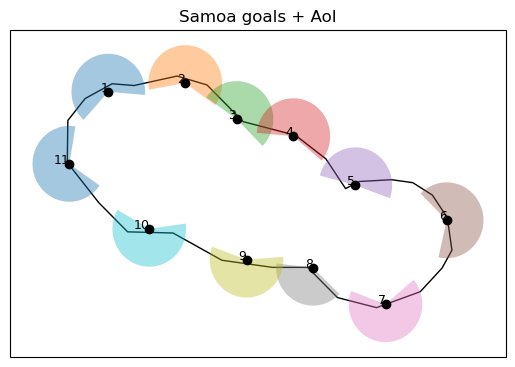

In [6]:
wrapper.plot_configuration()

## Build, run, postprocess

In [7]:
wrapper.build_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [8]:
wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [12]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    744
Name: count, dtype: int64

In [13]:
result = wrapper.postprocess_cases()
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
result.to_netcdf(out_nc)